In [2]:
import requests
import time

HEADERS = {
    "User-Agent": "comuni-generator/1.0"
}

def genera_lista_comuni_provincia(provincia):

    print(f"Scarico comuni provincia: {provincia}")

    # 1. Trova area provincia via Nominatim
    nominatim_url = "https://nominatim.openstreetmap.org/search"

    r = requests.get(
        nominatim_url,
        params={
            "q": f"Provincia di {provincia}, Italia",
            "format": "jsonv2",
            "limit": 1
        },
        headers=HEADERS
    )

    r.raise_for_status()
    data = r.json()

    if not data:
        raise ValueError("Provincia non trovata")

    osm_id = int(data[0]["osm_id"])

    # 2. Overpass query comuni (admin level 8 = comuni)
    query = f"""
    [out:json][timeout:300];

    area({3600000000 + osm_id})->.searchArea;

    relation
      ["boundary"="administrative"]
      ["admin_level"="8"]
      (area.searchArea);

    out center;
    """

    r = requests.post(
        "https://overpass-api.de/api/interpreter",
        data=query,
        headers=HEADERS,
        timeout=300
    )

    r.raise_for_status()
    elements = r.json()["elements"]

    comuni = []

    for el in elements:

        tags = el.get("tags", {})
        nome = tags.get("name")

        center = el.get("center", {})

        lat = center.get("lat")
        lon = center.get("lon")

        if nome and lat and lon:
            comuni.append((nome, float(lat), float(lon)))

    # ordina alfabeticamente
    comuni.sort(key=lambda x: x[0])

    # 3. stampa in formato Python ready-to-copy
    print("\nCOPIA E INCOLLA QUESTO:\n")

    print("comuni = [")
    for c in comuni:
        print(f"    {c},")
    print("]")

    print(f"\nTotale comuni: {len(comuni)}")

    return comuni


# ESEMPIO
#genera_lista_comuni_provincia("Bergamo")

In [ ]:
import time
import requests
import pandas as pd

from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL


# =====================================================
# CONFIG
# =====================================================

START_DATE = "2020-12-31"
END_DATE = "2025-12-31"

REQUEST_DELAY = 20

WEATHER_TABLE = "bergamo_weather_1980_2020"
CHECKPOINT_TABLE = "comuni_completati2"

DB_CONFIG = {
    "host": "aws-0-eu-west-1.pooler.supabase.com",
    "port": 6543,
    "database": "postgres",
    "user": "postgres.palaoxigjbvbrgdnbstd",
    "password": "@ghZ2XjxsdL_*m*"
}

# tua funzione
comuni = genera_lista_comuni_provincia("Bergamo")


# =====================================================
# DB
# =====================================================

url = URL.create(
    drivername="postgresql+psycopg2",
    username=DB_CONFIG["user"],
    password=DB_CONFIG["password"],
    host=DB_CONFIG["host"],
    port=DB_CONFIG["port"],
    database=DB_CONFIG["database"]
)

engine = create_engine(url)


# =====================================================
# CREA TABELLA CHECKPOINT
# =====================================================

with engine.begin() as conn:

    conn.execute(text(f"""
        CREATE TABLE IF NOT EXISTS {CHECKPOINT_TABLE}
        (
            comune TEXT PRIMARY KEY,
            data_elaborazione TIMESTAMP DEFAULT NOW()
        )
    """))


# =====================================================
# LEGGI COMUNI GIÀ ELABORATI
# =====================================================

try:

    completati = pd.read_sql(
        f"SELECT comune FROM {CHECKPOINT_TABLE}",
        engine
    )["comune"].tolist()

except Exception:

    completati = []

print(f"Comuni già elaborati: {len(completati)}")

comuni = [
    comune
    for comune in comuni
    if comune[0] not in completati
]

print(f"Comuni da elaborare: {len(comuni)}")


# =====================================================
# SESSIONE HTTP
# =====================================================

session = requests.Session()

retry_strategy = Retry(
    total=5,
    backoff_factor=10,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"]
)

adapter = HTTPAdapter(max_retries=retry_strategy)

session.mount("https://", adapter)
session.mount("http://", adapter)

HEADERS = {
    "User-Agent": "weather-downloader/1.0"
}


# =====================================================
# DOWNLOAD DATI
# =====================================================

def scarica_dati(nome, lat, lon):

    api_url = (
        "https://archive-api.open-meteo.com/v1/archive"
        f"?latitude={lat}"
        f"&longitude={lon}"
        f"&start_date={START_DATE}"
        f"&end_date={END_DATE}"
        "&daily=temperature_2m_mean,rain_sum,snowfall_sum"
        "&timezone=Europe/Rome"
    )

    tentativi = 0
    max_tentativi = 5

    while tentativi < max_tentativi:

        try:

            print(f"\nScarico dati per {nome}")

            response = session.get(
                api_url,
                headers=HEADERS,
                timeout=120
            )

            if response.status_code == 429:

                wait_time = 60 * (tentativi + 1)

                print(
                    f"429 per {nome} "
                    f"-> attendo {wait_time}s"
                )

                time.sleep(wait_time)

                tentativi += 1
                continue

            response.raise_for_status()

            data = response.json()

            if "daily" not in data:

                print(f"Nessun dato per {nome}")

                return None

            df = pd.DataFrame({
                "date": data["daily"]["time"],
                "temperature_mean": data["daily"]["temperature_2m_mean"],
                "rain_sum": data["daily"]["rain_sum"],
                "snowfall_sum": data["daily"]["snowfall_sum"]
            })

            df["date"] = pd.to_datetime(df["date"])

            df["year"] = df["date"].dt.year
            df["month"] = df["date"].dt.month

            monthly = (
                df.groupby(["year", "month"])
                .agg({
                    "temperature_mean": "mean",
                    "rain_sum": "sum",
                    "snowfall_sum": "sum"
                })
                .reset_index()
            )

            monthly["comune"] = nome

            monthly = monthly[
                [
                    "comune",
                    "year",
                    "month",
                    "temperature_mean",
                    "rain_sum",
                    "snowfall_sum"
                ]
            ]

            return monthly

        except Exception as e:

            tentativi += 1

            wait_time = 30 * tentativi

            print(
                f"Errore {nome}: {e}"
            )

            print(
                f"Retry tra {wait_time}s"
            )

            time.sleep(wait_time)

    print(f"Fallito definitivamente: {nome}")

    return None


# =====================================================
# CICLO PRINCIPALE
# =====================================================

for nome, lat, lon in comuni:

    try:

        df = scarica_dati(nome, lat, lon)

        if df is None:

            continue

        print(
            f"Salvataggio DB: {nome} "
            f"({len(df)} righe)"
        )

        df.to_sql(
            WEATHER_TABLE,
            engine,
            if_exists="append",
            index=False,
            chunksize=1000,
            method="multi"
        )

        checkpoint = pd.DataFrame(
            [{"comune": nome}]
        )

        checkpoint.to_sql(
            CHECKPOINT_TABLE,
            engine,
            if_exists="append",
            index=False
        )

        print(f"✓ COMPLETATO: {nome}")

    except Exception as e:

        print(
            f"Errore salvataggio {nome}: {e}"
        )

    time.sleep(REQUEST_DELAY)


# =====================================================
# REPORT FINALE
# =====================================================

try:

    totale = pd.read_sql(
        f"SELECT COUNT(*) AS n FROM {WEATHER_TABLE}",
        engine
    )

    print(
        f"\nTotale record nel DB: "
        f"{totale.iloc[0]['n']:,}"
    )

except Exception as e:

    print(f"Errore report finale: {e}")

print("\nFine elaborazione.")

Scarico comuni provincia: Bergamo

COPIA E INCOLLA QUESTO:

comuni = [
    ('Adrara San Martino', 45.7158824, 9.9618999),
    ('Adrara San Rocco', 45.7300406, 9.9703401),
    ("Albano Sant'Alessandro", 45.6874046, 9.77294),
    ('Albino', 45.7589511, 9.81988),
    ('Algua', 45.8176115, 9.73468),
    ('Almenno San Bartolomeo', 45.7480268, 9.569563),
    ('Almenno San Salvatore', 45.7514808, 9.5897753),
    ('Almè', 45.7385326, 9.614686),
    ('Alzano Lombardo', 45.75305, 9.7141016),
    ('Ambivere', 45.7213428, 9.5394612),
    ('Antegnate', 45.4861075, 9.797647),
    ('Arcene', 45.5742111, 9.6107808),
    ('Ardesio', 45.9471116, 9.8968094),
    ("Arzago d'Adda", 45.4740048, 9.5656935),
    ('Averara', 46.012445, 9.628475),
    ('Aviatico', 45.7907963, 9.7911409),
    ('Azzano San Paolo', 45.6584406, 9.6813617),
    ('Azzone', 45.9668198, 10.1388663),
    ('Bagnatica', 45.6568337, 9.7662758),
    ('Barbata', 45.4566279, 9.7713797),
    ('Bariano', 45.5137613, 9.7069974),
    ('Barzana', 

In [6]:

import time
import requests
import pandas as pd

from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

from sqlalchemy import create_engine
from sqlalchemy.engine import URL


# =====================================================
# CONFIG
# =====================================================

START_DATE = "1980-01-01"
END_DATE = "2020-12-31"

OUTPUT_CSV = "lecco_weather_1980_2020.csv"

BATCH_SIZE = 20

REQUEST_DELAY_BETWEEN_BATCHES = 15

DB_CONFIG = {
    "host": "aws-0-eu-west-1.pooler.supabase.com",
    "port": 6543,
    "database": "postgres",
    "user": "postgres.palaoxigjbvbrgdnbstd",
    "password": "@ghZ2XjxsdL_*m*"
}


# =====================================================
# COMUNI
# =====================================================

comuni = genera_lista_comuni_provincia("Lecco")

# formato atteso:
# [
#     ("Lecco", 45.8566, 9.3977),
#     ("Merate", 45.6984, 9.4201),
#     ...
# ]


# =====================================================
# DATABASE
# =====================================================

url = URL.create(
    drivername="postgresql+psycopg2",
    username=DB_CONFIG["user"],
    password=DB_CONFIG["password"],
    host=DB_CONFIG["host"],
    port=DB_CONFIG["port"],
    database=DB_CONFIG["database"]
)

engine = create_engine(url)


# =====================================================
# SESSION HTTP
# =====================================================

session = requests.Session()

retry_strategy = Retry(
    total=5,
    backoff_factor=2,
    status_forcelist=[500, 502, 503, 504],
    allowed_methods=["GET"]
)

adapter = HTTPAdapter(max_retries=retry_strategy)

session.mount("https://", adapter)
session.mount("http://", adapter)


# =====================================================
# DOWNLOAD BATCH
# =====================================================

def scarica_batch(comuni_batch):

    latitudes = ",".join(
        str(lat)
        for _, lat, _ in comuni_batch
    )

    longitudes = ",".join(
        str(lon)
        for _, _, lon in comuni_batch
    )

    url = (
        "https://archive-api.open-meteo.com/v1/archive"
        f"?latitude={latitudes}"
        f"&longitude={longitudes}"
        f"&start_date={START_DATE}"
        f"&end_date={END_DATE}"
        "&daily=temperature_2m_mean"
        ",rain_sum"
        ",snowfall_sum"
        "&timezone=Europe/Rome"
    )

    tentativi = 0
    max_tentativi = 10

    while tentativi < max_tentativi:

        try:

            response = session.get(
                url,
                timeout=300
            )

            if response.status_code == 429:

                retry_after = response.headers.get(
                    "Retry-After"
                )

                if retry_after:
                    wait_time = int(retry_after)
                else:
                    wait_time = 60

                print(
                    f"429 ricevuto "
                    f"-> attendo {wait_time}s"
                )

                time.sleep(wait_time)

                tentativi += 1

                continue

            response.raise_for_status()

            return response.json()

        except Exception as e:

            tentativi += 1

            wait_time = min(
                30 * tentativi,
                300
            )

            print(
                f"Errore batch "
                f"({tentativi}/{max_tentativi})"
            )

            print(e)

            print(
                f"Retry tra "
                f"{wait_time}s"
            )

            time.sleep(wait_time)

    raise RuntimeError(
        "Download batch fallito"
    )


# =====================================================
# ELABORAZIONE BATCH
# =====================================================

def processa_batch(comuni_batch):

    data = scarica_batch(comuni_batch)

    risultati = []

    if not isinstance(data, list):

        data = [data]

    for comune_info, meteo in zip(
        comuni_batch,
        data
    ):

        nome, lat, lon = comune_info

        if "daily" not in meteo:

            print(
                f"Nessun dato per "
                f"{nome}"
            )

            continue

        daily = meteo["daily"]

        df = pd.DataFrame({
            "date": daily["time"],
            "temperature_mean":
                daily["temperature_2m_mean"],
            "rain_sum":
                daily["rain_sum"],
            "snowfall_sum":
                daily["snowfall_sum"]
        })

        df["date"] = pd.to_datetime(
            df["date"]
        )

        monthly = (
            df.groupby(
                [
                    df["date"].dt.year,
                    df["date"].dt.month
                ]
            )
            .agg({
                "temperature_mean": "mean",
                "rain_sum": "sum",
                "snowfall_sum": "sum"
            })
            .reset_index()
        )

        monthly.columns = [
            "year",
            "month",
            "temperature_mean",
            "rain_sum",
            "snowfall_sum"
        ]

        monthly["comune"] = nome

        risultati.append(monthly)

    return risultati


# =====================================================
# MAIN
# =====================================================

all_data = []

numero_batch = (
    len(comuni) + BATCH_SIZE - 1
) // BATCH_SIZE

for i in range(
    0,
    len(comuni),
    BATCH_SIZE
):

    batch = comuni[
        i:i + BATCH_SIZE
    ]

    batch_num = (
        i // BATCH_SIZE
    ) + 1

    print(
        f"\nBatch "
        f"{batch_num}/{numero_batch}"
    )

    try:

        risultati = processa_batch(
            batch
        )

        all_data.extend(
            risultati
        )

        if all_data:

            temp_df = pd.concat(
                all_data,
                ignore_index=True
            )

            temp_df.to_csv(
                OUTPUT_CSV,
                index=False
            )

            print(
                "Salvataggio "
                "parziale completato"
            )

        time.sleep(
            REQUEST_DELAY_BETWEEN_BATCHES
        )

    except Exception as e:

        print(
            f"Errore batch "
            f"{batch_num}:"
        )

        print(e)

        time.sleep(60)


# =====================================================
# EXPORT CSV
# =====================================================

if not all_data:

    print(
        "Nessun dato scaricato"
    )

    raise SystemExit()


final_df = pd.concat(
    all_data,
    ignore_index=True
)

final_df = final_df[
    [
        "comune",
        "year",
        "month",
        "temperature_mean",
        "rain_sum",
        "snowfall_sum"
    ]
]

final_df.to_csv(
    OUTPUT_CSV,
    index=False
)

print(
    f"\nCSV finale salvato: "
    f"{OUTPUT_CSV}"
)


# =====================================================
# CARICAMENTO POSTGRESQL
# =====================================================

table_name = (
    OUTPUT_CSV
    .replace(".csv", "")
    .replace("-", "_")
    .lower()
)

try:

    print(
        f"Caricamento tabella "
        f"{table_name}"
    )

    final_df.to_sql(
        table_name,
        engine,
        if_exists="replace",
        index=False,
        chunksize=1000,
        method="multi"
    )

    print(
        f"Tabella creata: "
        f"{table_name}"
    )

    print(
        f"Righe caricate: "
        f"{len(final_df):,}"
    )

except Exception as e:

    print(
        "Errore caricamento DB:"
    )

    print(e)



Scarico comuni provincia: Lecco

COPIA E INCOLLA QUESTO:

comuni = [
    ('Abbadia Lariana', 45.8964877, 9.3566953),
    ('Airuno', 45.7558796, 9.4209479),
    ('Annone di Brianza', 45.8026376, 9.3305397),
    ('Ballabio', 45.9030946, 9.4203478),
    ('Barzago', 45.7540728, 9.3177465),
    ('Barzanò', 45.7302941, 9.3118763),
    ('Barzio', 45.9536827, 9.4962746),
    ('Bellano', 46.0459774, 9.3216327),
    ('Bosisio Parini', 45.7974174, 9.2938789),
    ('Brivio', 45.7551845, 9.4357897),
    ('Bulciago', 45.7550538, 9.2885337),
    ('Calco', 45.7246624, 9.4264024),
    ('Calolziocorte', 45.7952521, 9.4472945),
    ('Carenno', 45.8055939, 9.4750966),
    ('Casargo', 46.0393101, 9.4020586),
    ('Casatenovo', 45.6810706, 9.3266427),
    ('Cassago Brianza', 45.73419, 9.2869921),
    ('Cassina Valsassina', 45.9153376, 9.4853285),
    ('Castello di Brianza', 45.7564017, 9.3483937),
    ('Cernusco Lombardone', 45.6920427, 9.390571),
    ('Cesana Brianza', 45.8203895, 9.3004562),
    ('Civate'

KeyboardInterrupt: 

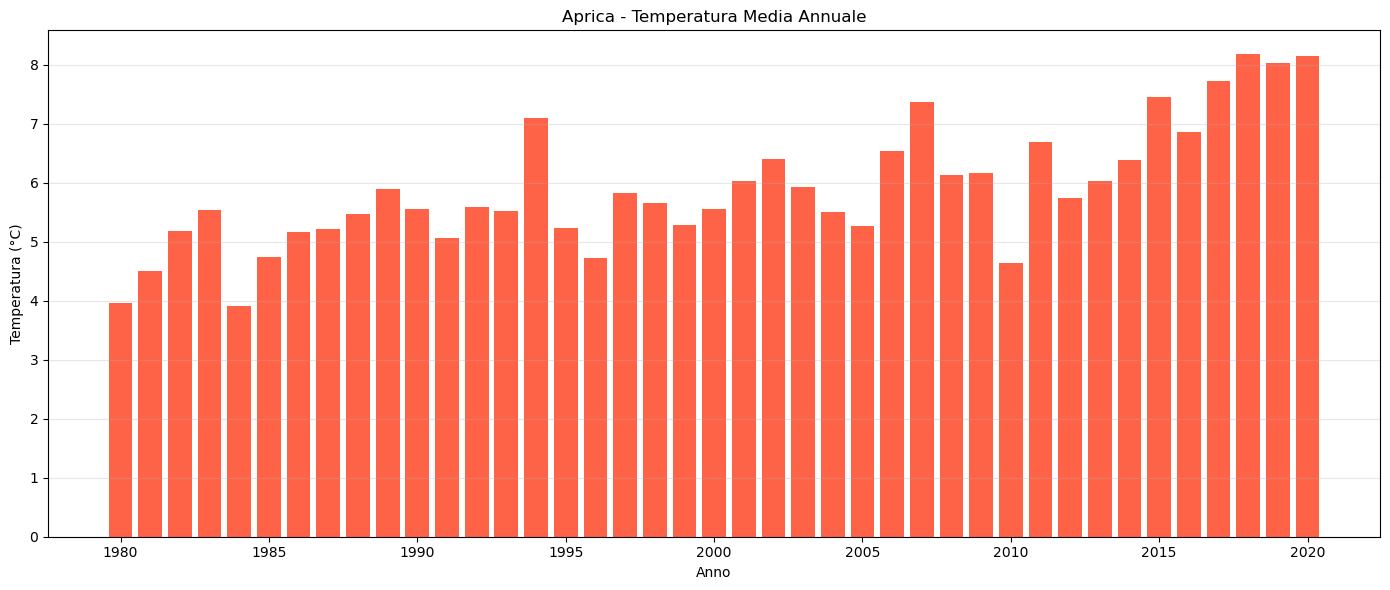

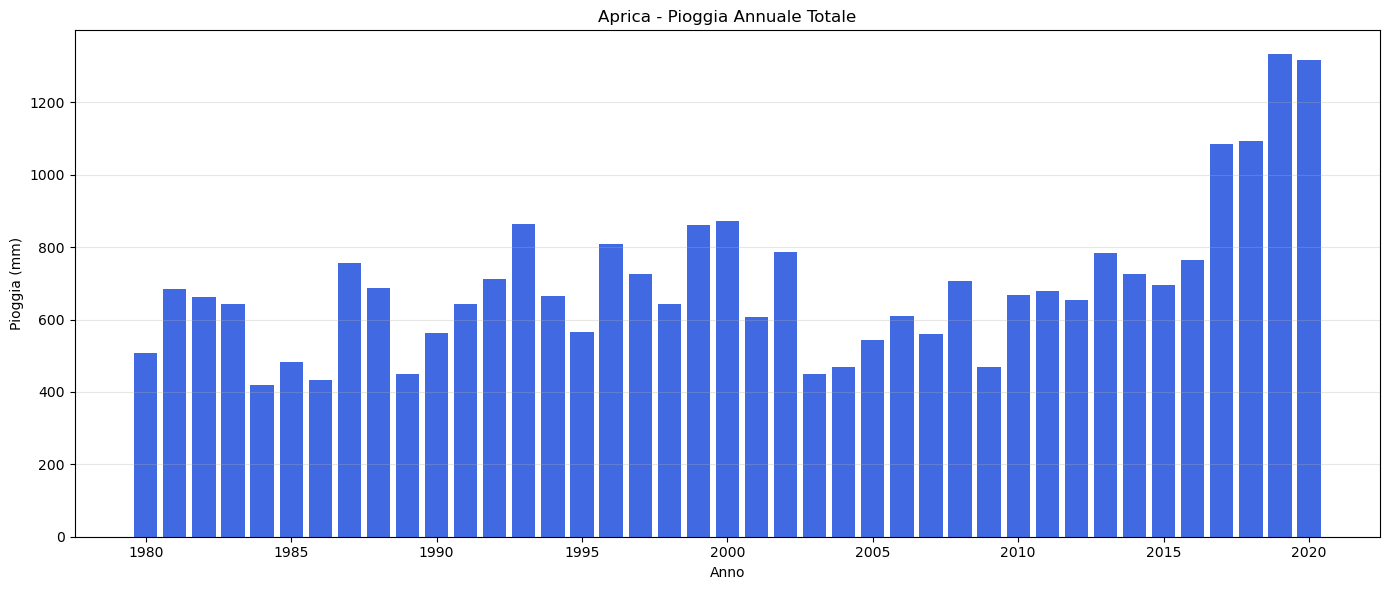

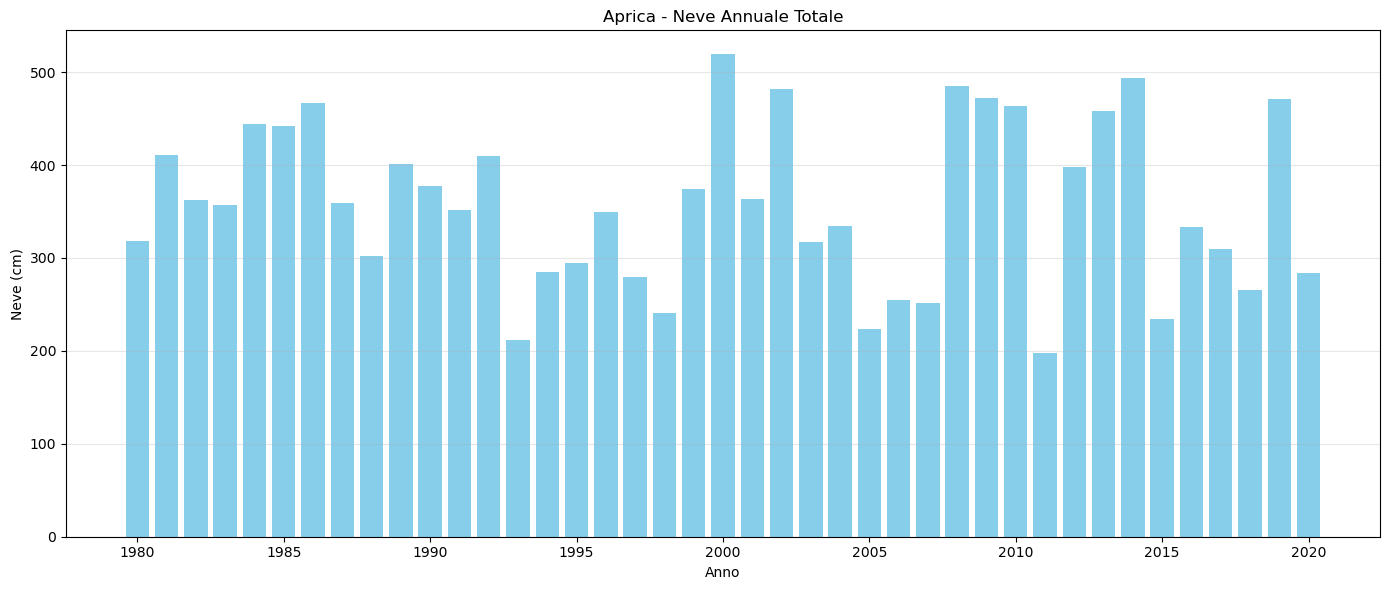

Grafici creati per Aprica


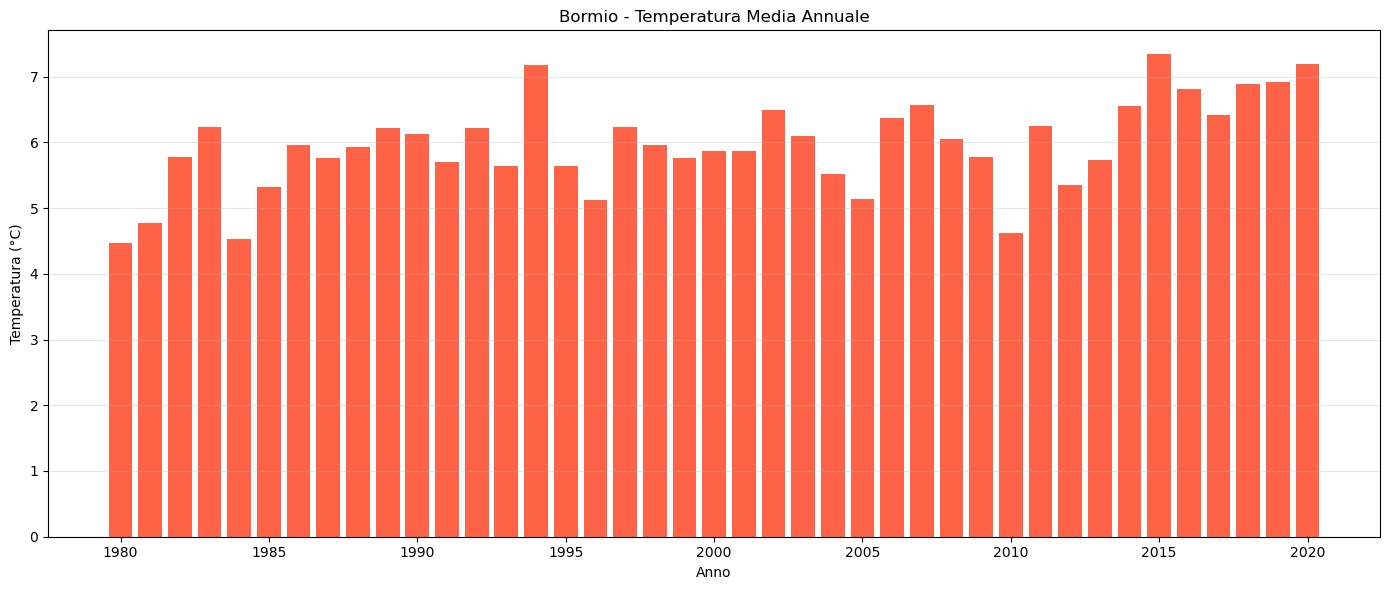

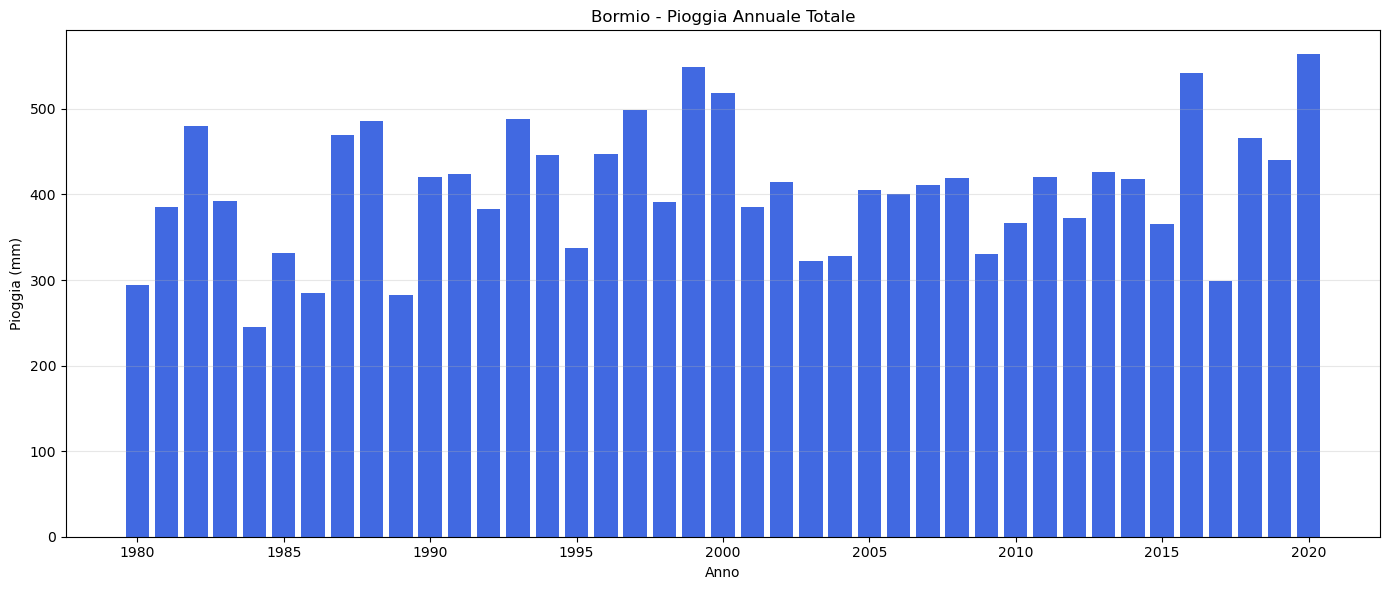

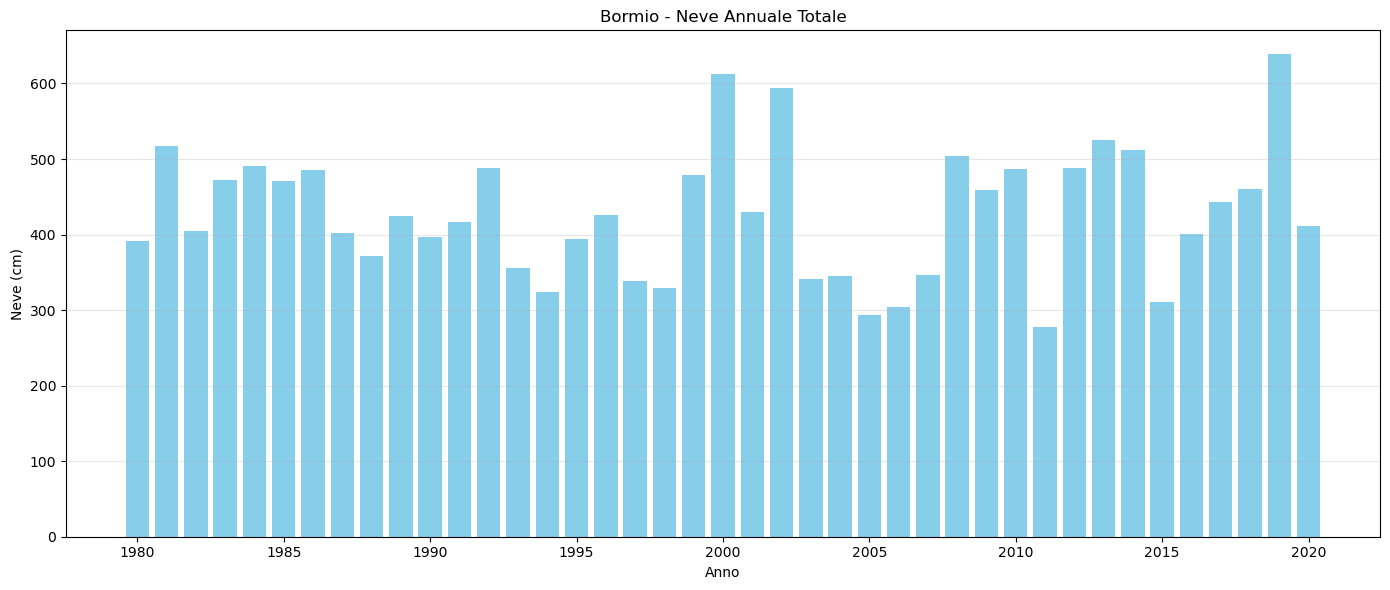

Grafici creati per Bormio


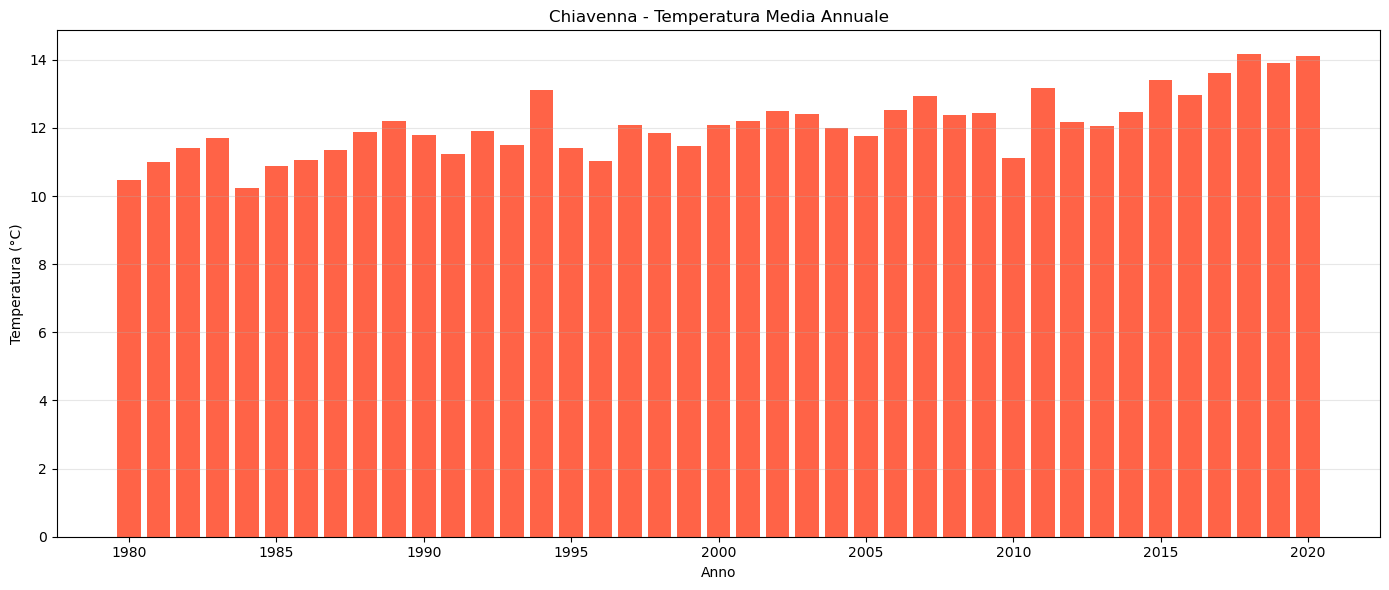

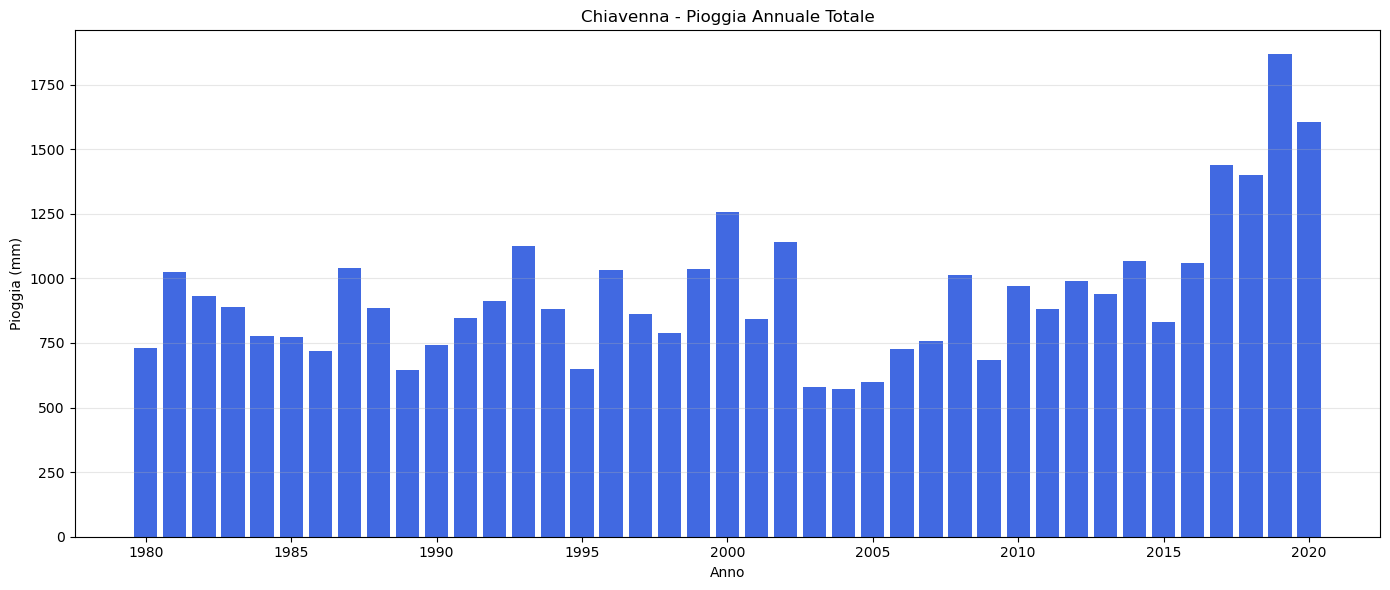

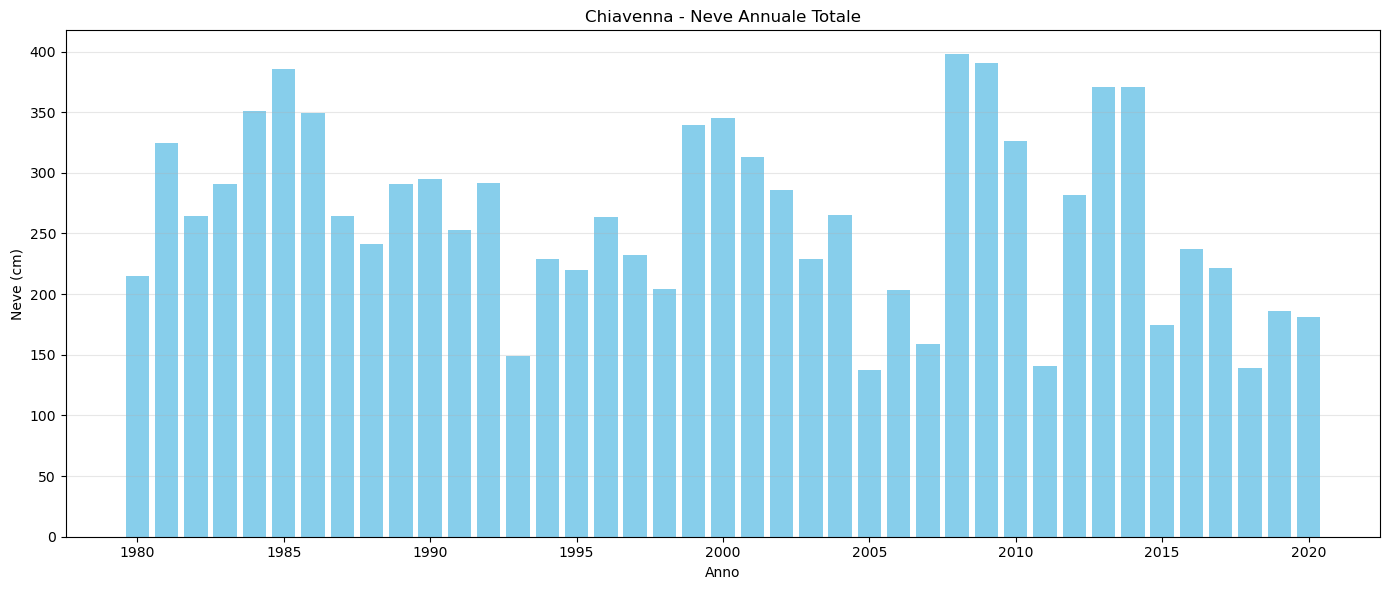

Grafici creati per Chiavenna


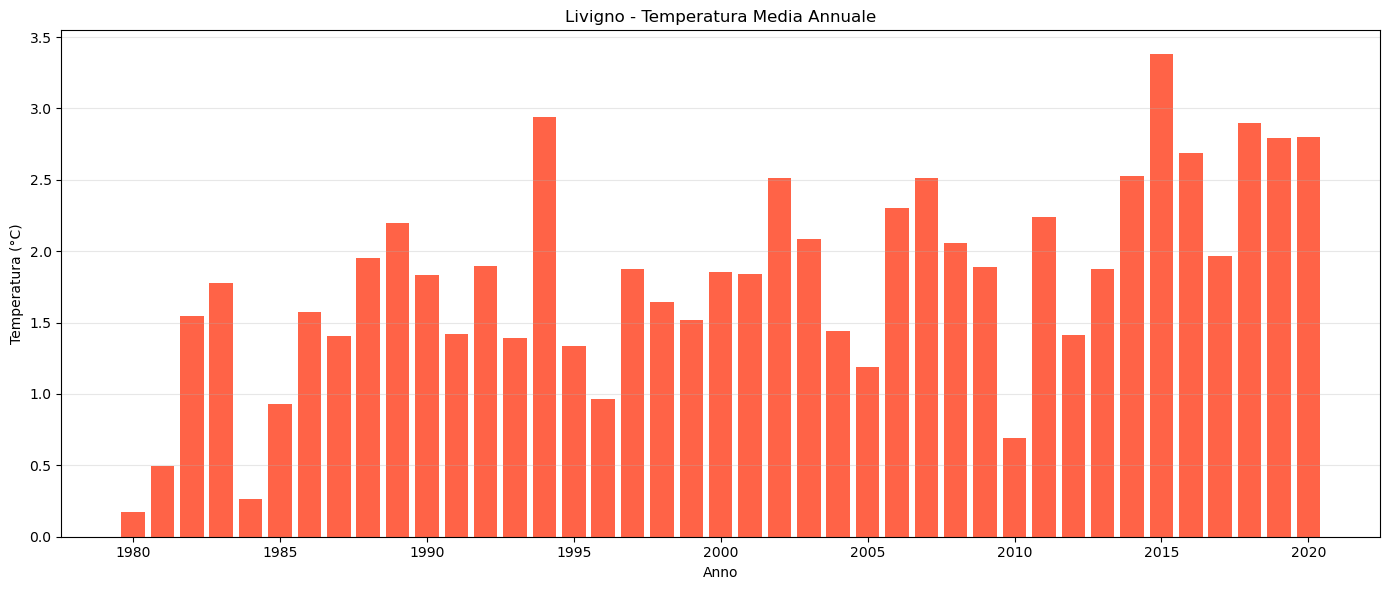

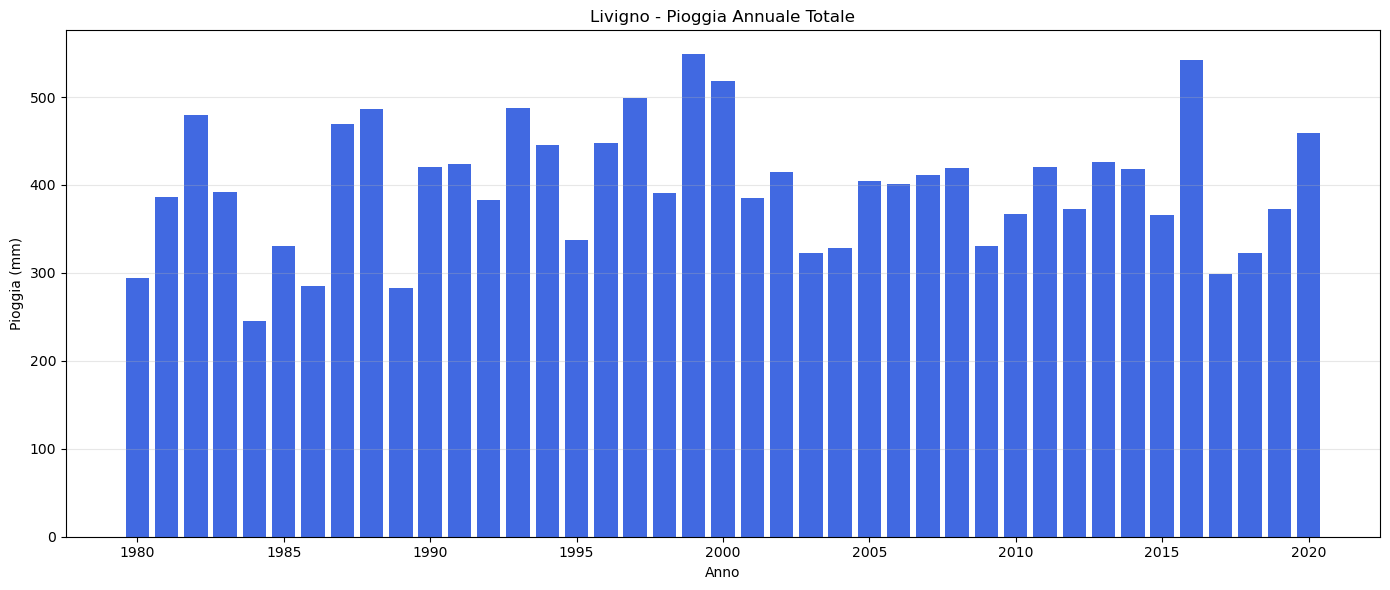

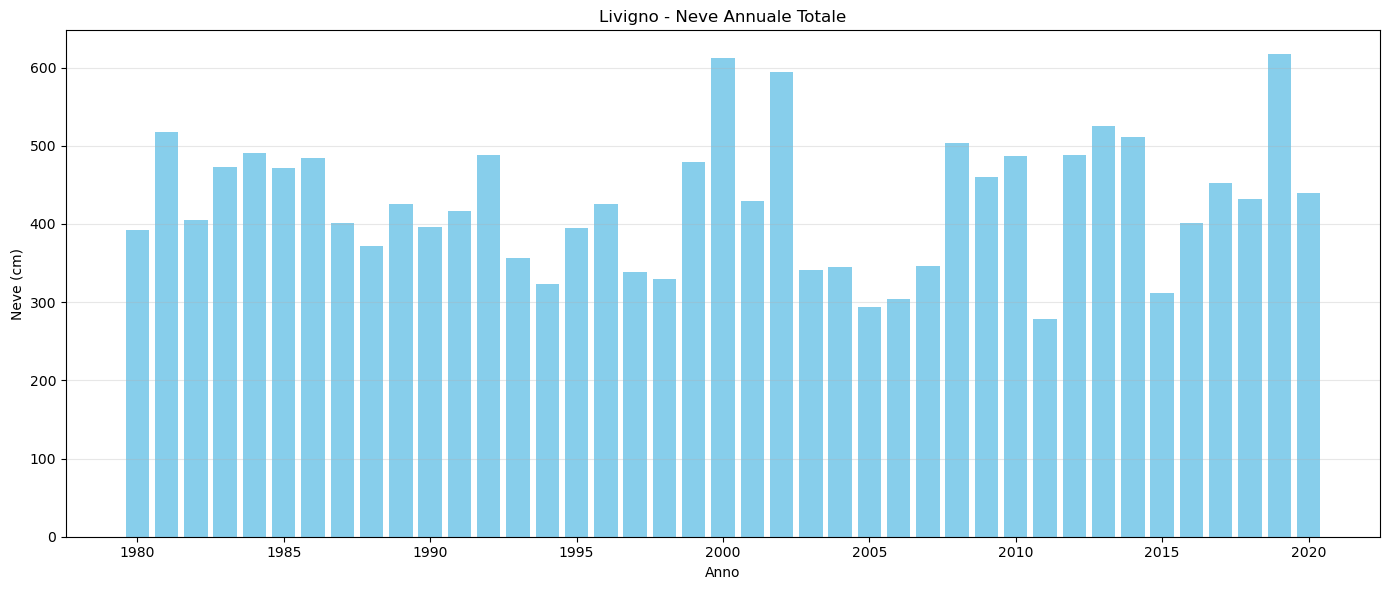

Grafici creati per Livigno


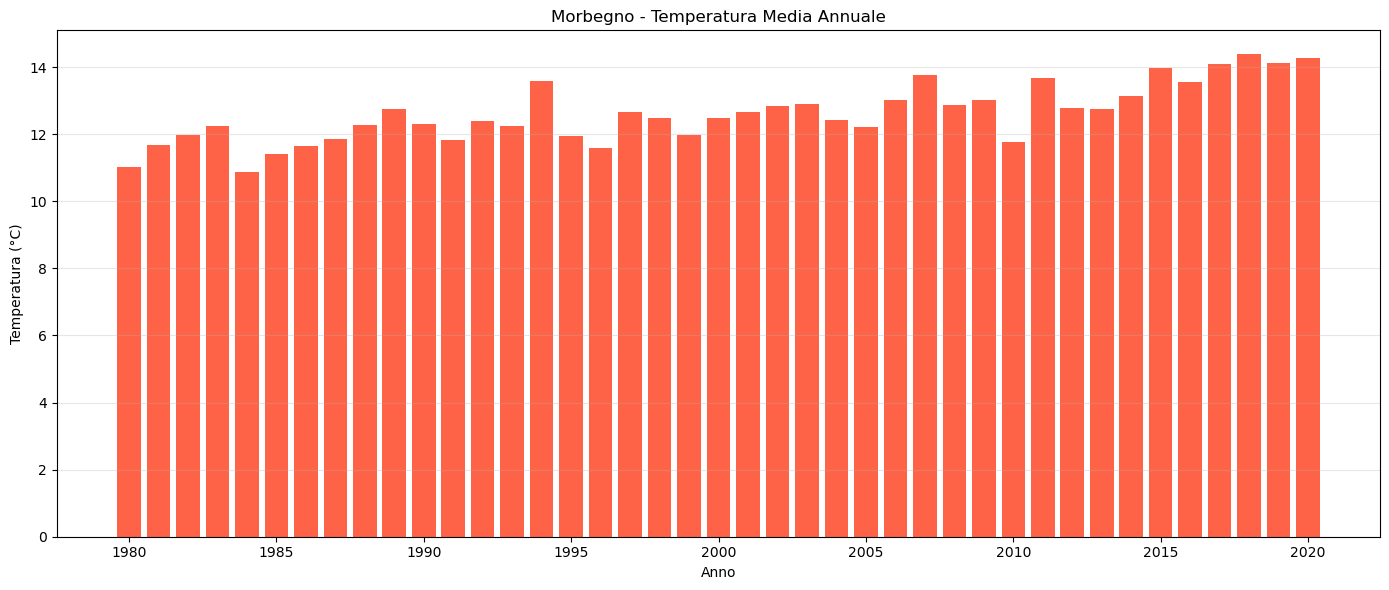

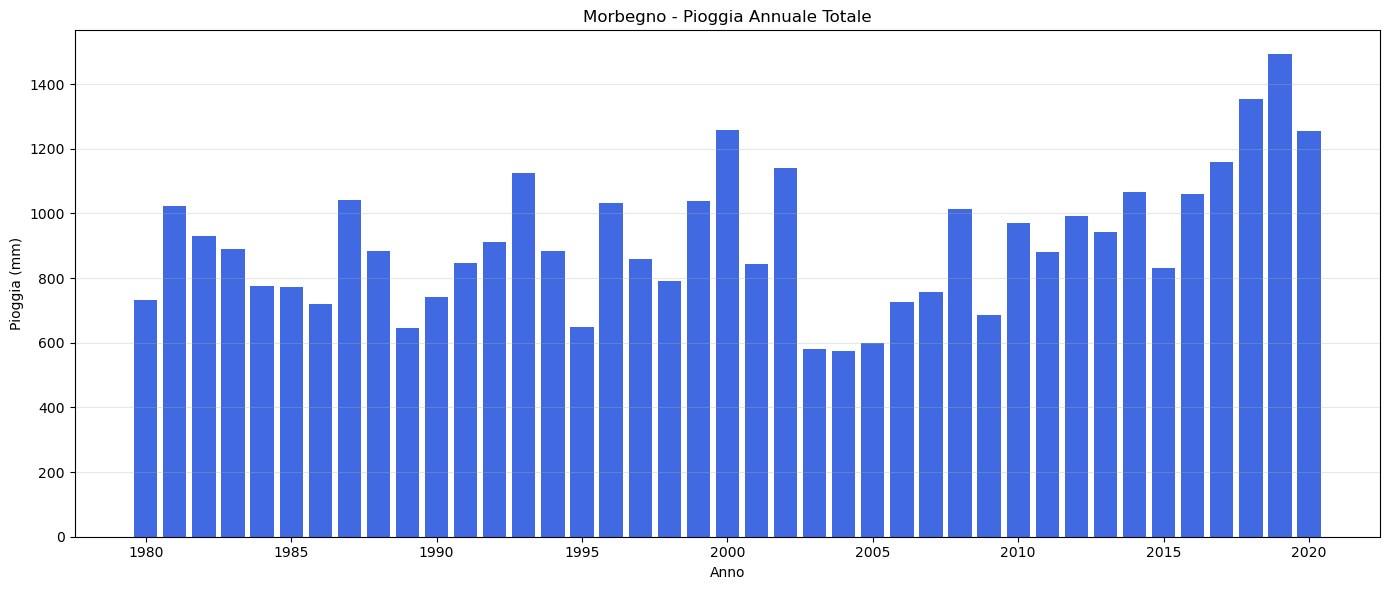

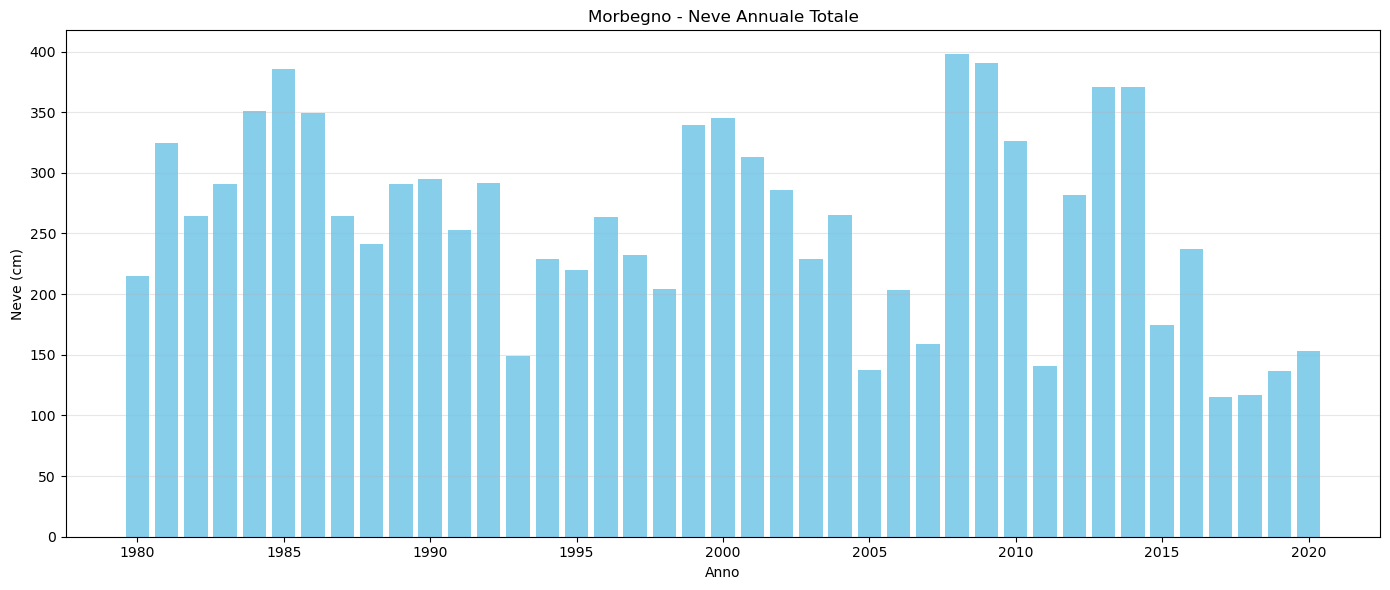

Grafici creati per Morbegno


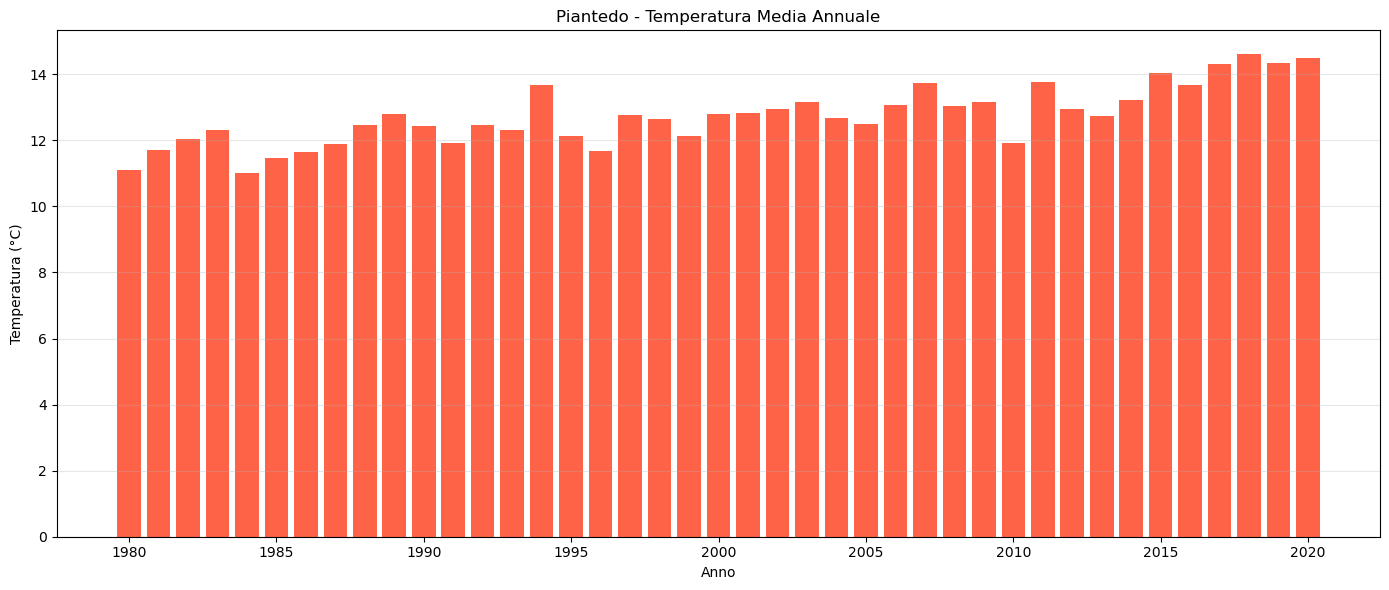

In [ ]:
##plot
import pandas as pd
import matplotlib.pyplot as plt
import os


CSV_FILE = "sondrio_weather_1980_2020.csv"

# cartelle output
TEMP_DIR = "grafici_temperatura"
RAIN_DIR = "grafici_pioggia"
SNOW_DIR = "grafici_neve"

os.makedirs(TEMP_DIR, exist_ok=True)
os.makedirs(RAIN_DIR, exist_ok=True)
os.makedirs(SNOW_DIR, exist_ok=True)



df = pd.read_csv(CSV_FILE)

#raggruppo per anno: temperatura-->media, neve e pioggia---> somma

annual = (
    df.groupby(["comune", "year"])
    .agg({
        "temperature_mean": "mean",
        "rain_sum": "sum",
        "snowfall_sum": "sum"
    })
    .reset_index()
)

#comuni presenti nel csv

comuni = annual["comune"].unique()

#creo i grafici

for comune in comuni:

    subset = annual[annual["comune"] == comune]

    years = subset["year"]


    # temp


    plt.figure(figsize=(14, 6))

    plt.bar(
        years,
        subset["temperature_mean"],
        color="tomato"
    )

    plt.title(f"{comune} - Temperatura Media Annuale")
    plt.xlabel("Anno")
    plt.ylabel("Temperatura (°C)")

    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()

    temp_path = f"{TEMP_DIR}/{comune}_temperatura.png"

    plt.savefig(temp_path, dpi=150)

    plt.show()

    plt.close()


    # pioggia

    plt.figure(figsize=(14, 6))

    plt.bar(
        years,
        subset["rain_sum"],
        color="royalblue"
    )

    plt.title(f"{comune} - Pioggia Annuale Totale")
    plt.xlabel("Anno")
    plt.ylabel("Pioggia (mm)")

    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()

    rain_path = f"{RAIN_DIR}/{comune}_pioggia.png"

    plt.savefig(rain_path, dpi=150)

    plt.show()

    plt.close()


    # neve

    plt.figure(figsize=(14, 6))

    plt.bar(
        years,
        subset["snowfall_sum"],
        color="skyblue"
    )

    plt.title(f"{comune} - Neve Annuale Totale")
    plt.xlabel("Anno")
    plt.ylabel("Neve (cm)")

    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()

    snow_path = f"{SNOW_DIR}/{comune}_neve.png"

    plt.savefig(snow_path, dpi=150)

    plt.show()

    plt.close()

    print(f"Grafici creati per {comune}")